# 04 · Análisis bivariado: actividad de los colectivos y calidad del aire

**Idea central.** Los colectivos son casi todos diésel, el combustible que más NOx emite; los autos a nafta emiten
sobre todo CO. Si los colectivos aportan una parte importante del NOx, cuanto menos circulan más tendría que bajar
el NOx, y bajar **más que el CO**. Antes de mirar los paros uno por uno (notebook 05), miramos **todos los días**
del período: hábiles, sábados, domingos, feriados y paros forman un **gradiente natural de actividad**.

**Variables:**
- `actividad_colectivo_vs_habil`: usos SUBE de los colectivos que circulan por CABA ese día, dividido por un
  día hábil normal típico de las 4 semanas anteriores y posteriores (1 = día hábil normal; 0,35 = domingo).
- `nox_816_ppb` y `co_816_ppm`: NOx y CO en el bloque de 8 a 16 h.
- `nox_co_816`: NOx relativo al CO (cociente NOx / CO). Resume en un número si bajó más el NOx o el CO; el
  viento lo afecta poco, porque diluye a los dos por igual.
- Meteorología diaria del SMN: viento, temperatura, humedad y lluvia.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "trenes_subte": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


## 1. Grupos de días

- **Hábil normal:** hábil, no feriado y con tren, subte y colectivos funcionando como siempre. Es la referencia.
- **Hábil de baja actividad:** lunes a viernes no feriado, pero con colectivo, tren o subte por debajo del 90%
  de su uso habitual (mediana del mismo día de la semana, ±4 semanas). No son paros de colectivos (ninguno tiene
  más del 2% de las líneas paradas): son vacaciones de invierno, 24 y 31 de diciembre, Jueves Santo, enero y días
  con problemas en trenes o subte. Quedan fuera de la referencia porque no son un día típico.
- **Paro de colectivos:** los 4 paros con más del 60% de las líneas de colectivo paradas.
- **Paro de trenes o subte:** los 3 paros con trenes (y a veces subte) sin servicio y los colectivos funcionando.

In [2]:
GRUPOS = ["Hábil normal", "Hábil baja actividad", "Paro de trenes o subte", "Sábado", "Feriado", "Domingo",
          "Paro de colectivos"]
# El grupo viene calculado en el pipeline (dim_calendario.grupo_dia): el mismo criterio en todo el TP.
d["grupo"] = d["grupo_dia"]
d.groupby("grupo").agg(estacion_dias=("fecha", "size"), dias=("fecha", "nunique"),
                       actividad_mediana=("actividad_colectivo_vs_habil", "median")).reindex(GRUPOS)

,estacion_dias,dias,actividad_mediana
grupo,,,
Hábil normal,1633,553,1.00
Hábil baja actividad,336,114,0.87
Paro de trenes o subte,9,3,0.82
Sábado,403,139,0.60
Feriado,157,53,0.36
Domingo,400,138,0.35
Paro de colectivos,12,4,0.21


## 2. El gradiente: menos colectivos, menos NOx

Para que la comparación sea justa, cada día se compara **con su propia estación** (La Boca tiene un NOx/CO
mucho más alto que las otras dos, y los paros de 2024 solo tienen datos ahí). El índice es la media geométrica
del grupo dividida por la de los días hábiles normales de la misma estación, promediado entre estaciones
(**hábil normal = 100**).

In [3]:
VARS = {"nox_816_ppb": "NOx", "co_816_ppm": "CO", "nox_co_816": "NOx/CO"}
filas = []
for col, nombre in VARS.items():
    x = d[d[col] > 0].copy()
    x["log"] = np.log(x[col])
    ref = x[x.grupo == "Hábil normal"].groupby("estacion")["log"].mean()
    x["desvio"] = x["log"] - x["estacion"].map(ref)
    # promedio dentro de cada estación y después entre estaciones (cada estación pesa igual)
    por_est = x.groupby(["grupo", "estacion"])["desvio"].mean()
    filas.append((np.exp(por_est.groupby("grupo").mean()) * 100).rename(nombre))
indice = pd.concat(filas, axis=1).reindex(GRUPOS)
indice.insert(0, "actividad", d.groupby("grupo")["actividad_colectivo_vs_habil"].median().reindex(GRUPOS))
indice.insert(1, "viento (km/h)", d.drop_duplicates("fecha").groupby("grupo")["viento_kmh"].median().reindex(GRUPOS))
indice.style.format({"actividad": "{:.2f}", "viento (km/h)": "{:.1f}", "NOx": "{:.0f}", "CO": "{:.0f}", "NOx/CO": "{:.0f}"})

,actividad,viento (km/h),NOx,CO,NOx/CO
grupo,,,,,
Hábil normal,1.00,10.5,100,100,100
Hábil baja actividad,0.87,10.8,98,104,97
Paro de trenes o subte,0.82,14.0,60,82,73
Sábado,0.60,11.0,71,85,84
Feriado,0.36,10.5,51,72,71
Domingo,0.35,11.0,45,69,64
Paro de colectivos,0.21,12.5,68,116,57


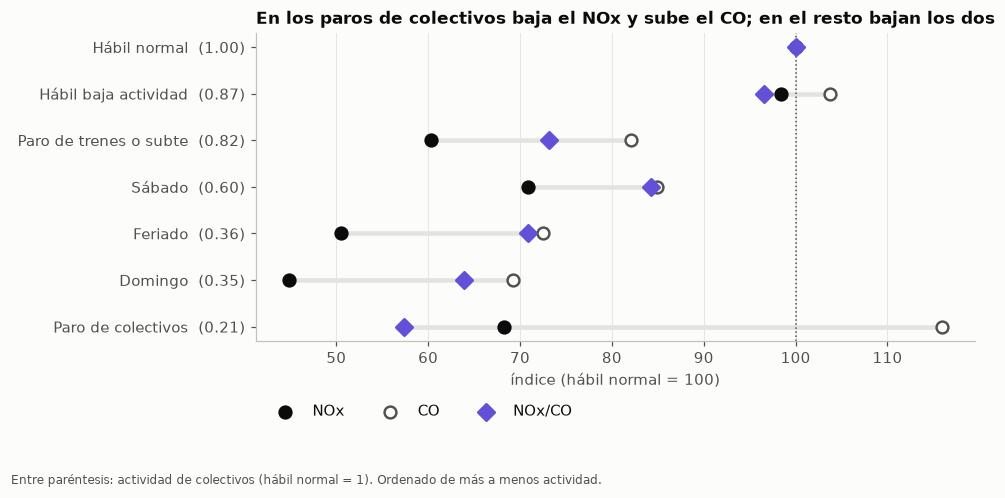

In [4]:
orden = indice.sort_values("actividad", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.2))
y = np.arange(len(orden))[::-1]
MARCAS = {"NOx": ("o", TINTA, TINTA), "CO": ("o", "#fcfcfb", TINTA_2), "NOx/CO": ("D", "#6250d6", "#6250d6")}
for nombre, (m, cara, borde) in MARCAS.items():
    ax.scatter(orden[nombre], y, marker=m, s=60, facecolor=cara, edgecolor=borde, linewidth=1.6,
               label=nombre, zorder=3)
for yi, (_, fila) in zip(y, orden.iterrows()):
    ax.plot([fila[list(MARCAS)].min(), fila[list(MARCAS)].max()], [yi, yi], color="#e4e3df", lw=3, zorder=1)
ax.axvline(100, color=TINTA_2, lw=1, ls=":")
ax.set_yticks(y, [f"{g}  ({a:.2f})" for g, a in zip(orden.index, orden.actividad)])
ax.set_xlabel("índice (hábil normal = 100)")
ax.set_title("En los paros de colectivos baja el NOx y sube el CO; en el resto bajan los dos")
ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0, -0.3))
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.06, "Entre paréntesis: actividad de colectivos (hábil normal = 1). Ordenado de más a menos actividad.",
         fontsize=8, color=TINTA_2)
plt.tight_layout()

**Lectura.**
- **Fines de semana y feriados:** baja todo (hay menos autos y menos colectivos y camiones), pero el NOx baja
  más que el CO. El domingo: NOx −55%, CO −31%.
- **Paros de colectivos:** el patrón cambia. El NOx baja (−32%) pero **el CO sube (+16%)**. Es consistente con
  que la gente reemplace el colectivo por auto, taxi o remís: menos diésel, más nafta. Es el único tipo de día en
  el que el CO sube. Lo mismo encontraron en Barcelona (González, Perdiguero y Sanz, 2021): con paro de colectivos,
  CO +12%.
- **Paros de trenes o subte:** baja todo, NOx (−40%) y CO (−18%), como en un fin de semana. Pero fueron días
  ventosos (14 km/h de mediana contra 10,5 de un hábil normal), y el viento baja todo.
- **Cuidado:** son 4 y 3 días, y esta tabla no descuenta la meteorología. Es una pista, no una conclusión.

In [5]:
# Para el dashboard: el índice por tipo de día en formato largo.
(indice.reset_index(names="grupo")
       .melt(id_vars=["grupo", "actividad", "viento (km/h)"], var_name="variable", value_name="indice")
       .rename(columns={"viento (km/h)": "viento_kmh"})
       .to_parquet(BASE / "indice_tipo_dia.parquet", index=False))
print(f"Guardado {BASE / 'indice_tipo_dia.parquet'}")

Guardado ../export/indice_tipo_dia.parquet


## 3. Día por día: actividad de colectivos contra NOx relativo al CO

Cada punto es una estación y un día. La línea es la mediana por tramos de actividad. Los eventos están
resaltados: **violeta** = paro de colectivos, **amarillo** = paro de trenes o subte.

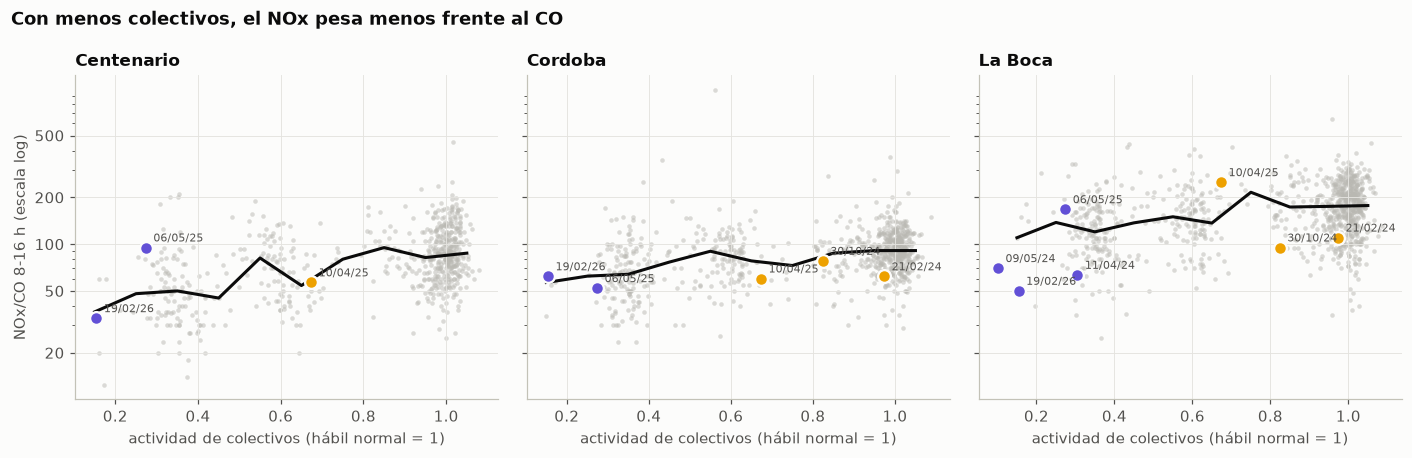

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
tramos = np.arange(0.1, 1.25, 0.1)
for ax, est in zip(axes, ESTACIONES):
    s = d[(d.estacion == est) & (d.nox_co_816 > 0)].dropna(subset=["actividad_colectivo_vs_habil"])
    ax.scatter(s.actividad_colectivo_vs_habil, s.nox_co_816, s=9, color=GRIS, alpha=0.5, linewidths=0)
    med = s.groupby(pd.cut(s.actividad_colectivo_vs_habil, tramos), observed=True)["nox_co_816"].agg(["median", "size"])
    med = med[med["size"] >= 5]
    ax.plot([i.mid for i in med.index], med["median"], color=TINTA, lw=2)
    for grupo, color in COLOR_EVENTO.items():
        ev = s[s.grupo_evento == grupo]
        ax.scatter(ev.actividad_colectivo_vs_habil, ev.nox_co_816, s=70, color=color, edgecolor="#fcfcfb",
                   linewidth=1.5, zorder=3)
        for _, r in ev.iterrows():
            ax.annotate(f"{r.fecha:%d/%m/%y}", (r.actividad_colectivo_vs_habil, r.nox_co_816),
                        xytext=(5, 4), textcoords="offset points", fontsize=7.5, color=TINTA_2)
    ax.set_yscale("log")
    ax.set_yticks([20, 50, 100, 200, 500], [20, 50, 100, 200, 500])
    ax.yaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(est.title())
    ax.set_xlabel("actividad de colectivos (hábil normal = 1)")
axes[0].set_ylabel("NOx/CO 8-16 h (escala log)")
fig.suptitle("Con menos colectivos, el NOx pesa menos frente al CO",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

In [7]:
from scipy.stats import spearmanr
print("Correlación de Spearman entre actividad y NOx/CO, todos los días:")
for est in ESTACIONES:
    s = d[(d.estacion == est)].dropna(subset=["actividad_colectivo_vs_habil", "nox_co_816"])
    rho, p = spearmanr(s.actividad_colectivo_vs_habil, s.nox_co_816)
    print(f"  {est:11s} rho = {rho:.2f}  (n = {len(s)}, p = {p:.1g})")

Correlación de Spearman entre actividad y NOx/CO, todos los días:
  CENTENARIO  rho = 0.41  (n = 641, p = 3e-27)
  CORDOBA     rho = 0.29  (n = 792, p = 1e-16)
  LA BOCA     rho = 0.27  (n = 911, p = 5e-17)


## 4. El otro factor: el viento

El viento diluye todo lo que se emite. Si un paro coincide con un día ventoso, el NOx baja aunque no haya
cambiado nada en el tránsito. ¿Cuánto afecta el viento a cada variable? Solo días hábiles normales, para que
la actividad sea la misma.

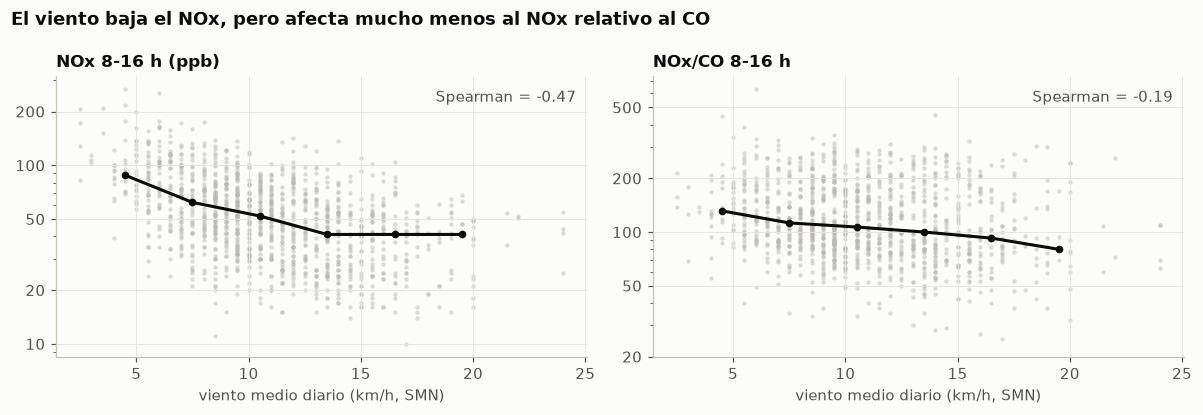

In [8]:
from matplotlib.ticker import NullFormatter
normales = d[d.grupo == "Hábil normal"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
tramos_v = np.arange(0, 32, 3)
for ax, (col, nombre) in zip(axes, [("nox_816_ppb", "NOx 8-16 h (ppb)"), ("nox_co_816", "NOx/CO 8-16 h")]):
    s = normales[normales[col] > 0].dropna(subset=["viento_kmh"])
    ax.scatter(s.viento_kmh, s[col], s=8, color=GRIS, alpha=0.5, linewidths=0)
    med = s.groupby(pd.cut(s.viento_kmh, tramos_v), observed=True)[col].agg(["median", "size"])
    med = med[med["size"] >= 10]
    ax.plot([i.mid for i in med.index], med["median"], color=TINTA, lw=2, marker="o", markersize=4)
    ax.set_yscale("log")
    ax.set(xlabel="viento medio diario (km/h, SMN)", title=nombre)
    ax.yaxis.set_minor_formatter(NullFormatter())
    rho, _ = spearmanr(s.viento_kmh, s[col])
    ax.text(0.98, 0.95, f"Spearman = {rho:.2f}", transform=ax.transAxes, ha="right", va="top", color=TINTA_2)
axes[0].set_yticks([10, 20, 50, 100, 200], [10, 20, 50, 100, 200])
axes[1].set_yticks([20, 50, 100, 200, 500], [20, 50, 100, 200, 500])
fig.suptitle("El viento baja el NOx, pero afecta mucho menos al NOx relativo al CO", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()

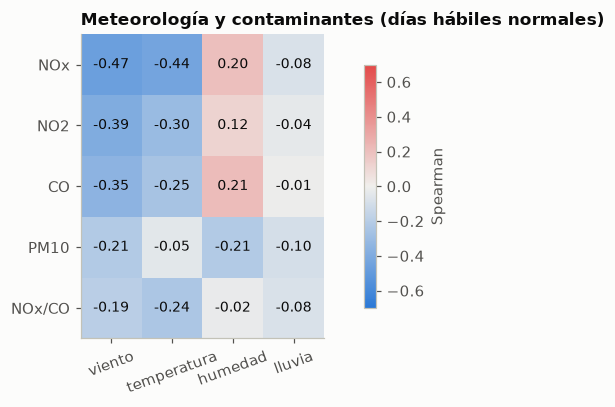

In [9]:
# Correlaciones de Spearman en días hábiles normales (rango: -1 a 1).
CONT = {"nox_816_ppb": "NOx", "no2_816_ppb": "NO2", "co_816_ppm": "CO", "pm10_816_ugm3": "PM10", "nox_co_816": "NOx/CO"}
METEO = {"viento_kmh": "viento", "temp_c": "temperatura", "humedad_pct": "humedad", "precipitacion_mm": "lluvia"}
corr = normales[list(CONT) + list(METEO)].corr(method="spearman").loc[list(CONT), list(METEO)]
corr = corr.rename(index=CONT, columns=METEO)

from matplotlib.colors import LinearSegmentedColormap
divergente = LinearSegmentedColormap.from_list("azul_rojo", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(corr.values, cmap=divergente, vmin=-0.7, vmax=0.7)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=20)
ax.set_yticks(range(len(corr.index)), corr.index)
ax.grid(False)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9, color=TINTA)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman")
ax.set_title("Meteorología y contaminantes (días hábiles normales)")
plt.tight_layout()

**Lectura.**
- Con más viento baja todo: NOx, NO2 y CO (Spearman entre −0,35 y −0,47). Con más temperatura también bajan
  (el invierno acumula contaminación, ver notebook 01).
- El **NOx relativo al CO depende mucho menos del viento** (−0,19): el viento diluye por igual al NOx y al CO.
  Por eso sirve para comparar días con distinta meteorología.
- Pero el cociente **no es inmune**: todavía depende algo del viento y de la temperatura (−0,24). Hay que
  ajustar igual, y eso hace el modelo del notebook 05.

## 5. Los eventos, comparación cruda

Cada evento contra la **mediana de los días hábiles normales del mismo mes y la misma estación**.
Es una comparación **sin ajustar por meteorología**: sirve para ver el orden de magnitud, no para concluir.
El ajuste por viento, temperatura y lluvia, con la prueba placebo, está en `05_eventos`.

In [10]:
ref = (d[d.grupo == "Hábil normal"].assign(periodo=lambda x: x.fecha.dt.to_period("M"))
         .groupby(["estacion", "periodo"])[list(VARS)].median())
ev = d[d.grupo_evento.notna()].assign(periodo=lambda x: x.fecha.dt.to_period("M"))
filas = []
for _, r in ev.iterrows():
    base = ref.loc[(r.estacion, r.periodo)]
    fila = {"fecha": r.fecha.date(), "evento": r.evento, "grupo": r.grupo_evento, "estación": r.estacion.title(),
            "actividad": r.actividad_colectivo_vs_habil, "viento": r.viento_kmh, "lluvia": r.precipitacion_mm}
    for col, nombre in VARS.items():
        fila[f"{nombre} %"] = (r[col] / base[col] - 1) * 100 if pd.notna(r[col]) else np.nan
    filas.append(fila)
crudo = pd.DataFrame(filas).sort_values(["grupo", "fecha", "estación"], ascending=[False, True, True])
crudo.round(1)

,fecha,evento,grupo,estación,actividad,viento,lluvia,NOx %,CO %,NOx/CO %
14,2024-02-21,Paro de trenes (La Fraternidad),trenes_subte,Centenario,1.00,12.00,0.00,NaN,NaN,NaN
7,2024-02-21,Paro de trenes (La Fraternidad),trenes_subte,Cordoba,1.00,12.00,0.00,-50.00,-28.60,-30.00
0,2024-02-21,Paro de trenes (La Fraternidad),trenes_subte,La Boca,1.00,12.00,0.00,25.70,0.00,25.70
18,2024-10-30,Paro de trenes y subte,trenes_subte,Centenario,0.80,14.00,0.00,NaN,0.00,NaN
11,2024-10-30,Paro de trenes y subte,trenes_subte,Cordoba,0.80,14.00,0.00,-27.10,-28.60,11.40
4,2024-10-30,Paro de trenes y subte,trenes_subte,La Boca,0.80,14.00,0.00,-37.70,-20.00,-28.30
19,2025-04-10,Paro general CGT con colectivos funcionando,trenes_subte,Centenario,0.70,17.00,0.00,-56.40,-40.00,-37.00
12,2025-04-10,Paro general CGT con colectivos funcionando,trenes_subte,Cordoba,0.70,17.00,0.00,-32.70,-14.30,-31.60
5,2025-04-10,Paro general CGT con colectivos funcionando,trenes_subte,La Boca,0.70,17.00,0.00,-27.50,-33.30,20.50
17,2024-04-11,Paro UTA,sin_colectivos,Centenario,0.30,15.50,0.00,NaN,0.00,NaN


In [11]:
print("Mediana de los cambios (%), por grupo de evento:")
crudo.groupby("grupo")[[f"{n} %" for n in VARS.values()]].median().round(0)

Mediana de los cambios (%), por grupo de evento:


,NOx %,CO %,NOx/CO %
grupo,,,
sin_colectivos,-23.00,0.00,-41.00
trenes_subte,-33.00,-24.00,-28.00


**Lectura.** Sin ajustar, en los paros de colectivos el NOx baja 23% y el CO queda igual (0%); en los paros de
trenes o subte bajan los dos (NOx −33%, CO −24%), en parte porque fueron días ventosos y el 10/04/2025 fue un paro
general (probablemente circularon menos camiones). **Esta tabla no alcanza para concluir**: hace falta comparar
cada evento contra lo que se esperaba para ese día según su meteorología (notebook 05).

## Hallazgos

1. **Hay un gradiente:** a menos actividad de colectivos, el NOx pesa menos frente al CO, en las tres estaciones
   (Spearman entre actividad y NOx relativo al CO de 0,27 a 0,41).
2. **Los paros de colectivos son el único tipo de día en el que el CO sube (+16%)** mientras el NOx baja (−32%):
   consistente con un reemplazo del colectivo por autos, el mismo mecanismo que en Europa, pero acá además sale el
   diésel de la calle.
3. **En los paros de trenes o subte baja todo**, NOx y CO, como en un fin de semana o un día ventoso.
4. **El viento es el principal factor de confusión:** baja mucho el NOx y el CO. Varios paros fueron días ventosos.
5. **Sin ajustar por meteorología no se puede afirmar nada sobre los paros:** eso lo hace el notebook 05.

**Siguiente:** `05_eventos` ajusta por viento, temperatura, lluvia, mes y día de la semana, y prueba si la
caída de cada paro es rara comparada con días normales (prueba placebo).